# 6. Apprentissage semi-supervisé : `Charpy conforme`

**Question** : les soudures **sans** résultat Charpy exploitable (on connaît leur composition et leur procédé, mais pas leur conformité) permettent-elles de mieux prédire la conformité Charpy que le modèle supervisé retenu par l'équipe ?

Le sujet demande d'appliquer **au moins une méthode semi-supervisée en justifiant son choix et sa pertinence**. On compare ici les **trois familles du cours (CM8)**, chacune face à **son équivalent supervisé**, avec exactement le même protocole que le notebook 3.

**Cible** : `Charpy conforme` telle que définie dans le notebook 2 (section 3.1) : la soudure atteint **47 J à −40 °C** (seuil EN ISO 2560-A). Règle : conforme si $E \ge 47$ J à $T \le -40$ °C, non conforme si $E < 47$ J à $T \ge -40$ °C, et, pour les soudures ayant à la fois T(28 J) et T(100 J), conformité déduite de T(47 J) obtenue par interpolation linéaire. Les autres lignes sont **non étiquetées** : ce sont les données $U$ du semi-supervisé.

**Ce qui est repris du notebook 3 (pour que la comparaison soit juste)**
- le **même découpage train / test** (relu dans `05_reporting/.../split_train_test.csv`) : le test n'est utilisé qu'une seule fois, à la fin ;
- la **même imputation métier** (`WeldImputer`) et la même variable construite (`CE_IIW`) ;
- le **modèle supervisé retenu par l'équipe** (relu dans `modele_retenu.json`), qui sert de modèle de base au self-training et de référence ;
- la même validation croisée groupée par publication (`StratifiedGroupKFold`, 5 plis, `random_state=42`).

Toutes les fonctions sont dans `utils_semi_supervise.py`, réutilisé par le notebook 7 (profil de résistance).

## Rappel : les trois familles de méthodes (cours CM8)

On dispose de $m$ exemples étiquetés $S = \{(x_i, y_i)\}_{i=1}^{m}$ et de $u$ exemples non étiquetés $U = \{x_i\}_{i=m+1}^{m+u}$. On cherche une fonction $h : x \mapsto y$ meilleure que celle apprise sur $S$ seul, en exploitant la structure de $U$.

| Famille | Principe | Hypothèse du cours | Méthodes testées | Référence supervisée |
|---|---|---|---|---|
| **Discriminante** (self-training) | Un modèle supervisé prédit $U$ ; les prédictions les plus **sûres** deviennent des pseudo-étiquettes ; on ré-entraîne et on itère (« version discriminante de CEM ») | Séparation en zone de faible densité | Self-training classique · Self-training équilibré par classe | Modèle retenu par l'équipe |
| **Graphe** (label spreading) | Graphe des $k$ plus proches voisins sur $S \cup U$ ; les étiquettes diffusent vers les voisins : $\tilde Y^* = (S + \lambda(D - W))^{-1} S Y$ | Lissité / variété | Label spreading | kNN |
| **Générative** (CEM semi-supervisé) | Une loi gaussienne par classe ; étape E (probabilités des non-étiquetées), C (affectation), M (ré-estimation sur $S \cup U$) | Lissité / clusters | CEM semi-supervisé | Mêmes gaussiennes apprises sur $S$ seul |

**Ces méthodes ne fonctionnent que si leurs hypothèses sont vérifiées** (Singh, Nowak & Zhu, 2008 ; Oliver et al., 2018) : on les teste en section 2 avant d'appliquer les méthodes.

## 0. Imports et paramètres

In [1]:
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import utils_semi_supervise as ssl

warnings.filterwarnings("ignore", category=UserWarning)
warnings.filterwarnings("ignore", category=FutureWarning)
sns.set_theme(style="whitegrid", context="notebook")

RANDOM_STATE = 42                 # même graine que les notebooks 3 et 5
N_FOLDS = 5                       # même nombre de plis
FRACTIONS = [0.1, 0.25, 0.5, 1.0] # part des étiquettes d'entraînement conservées (courbe d'apprentissage)
N_TIRAGES = 3                     # tirages par fraction < 100 % (lisse le bruit de la courbe)
N_BOOT = 500                      # rééchantillonnages bootstrap
METRIQUE = "Accuracy_ponderee"    # métrique principale (justification en section 3)

CIBLE = "Charpy conforme"
METHODE_REF = "A_sans_selection"  # le semi-supervisé utilise toutes les variables, comme la méthode A

P_DONNEES = Path("..") / "1. Données"
P_REF = P_DONNEES / "05_reporting" / "prediction_Charpy conforme" / "Charpy_conforme"
P_SORTIE = P_DONNEES / "05_reporting" / "semi_supervise" / "Charpy_conforme"
P_FIG = Path("..") / "3. Résultats" / "figures"
P_FIG.mkdir(parents=True, exist_ok=True)

def savefig(nom):
    plt.savefig(P_FIG / f"ssl_charpy_{nom}.png", dpi=150, bbox_inches="tight")

## 1. Données

- Entrées : les mêmes que le notebook 3. Toutes les cibles sont retirées (une cible ne doit pas servir à en prédire une autre), ainsi que `Charpy temperature` et `Charpy impact toughness`, déjà supprimées dans le notebook 2 car elles **construisent** l'étiquette.
- **Non-étiquetées $U$** : les lignes où `Charpy conforme` est vide. Celles qui viennent d'une **publication du test** sont retirées : même sans étiquette, leurs entrées décrivent les soudures du test, et le graphe ou le self-training pourraient s'en servir pour « préparer » le test.

In [2]:
df = pd.read_csv(P_DONNEES / "02_intermediate" / "welddb_processed_vf.csv", sep=";")
corresp = pd.read_csv(P_DONNEES / "02_intermediate" / "correspondance_between_names_units_vf.csv", sep=";")
TARGETS = corresp.loc[corresp["Role"] == "Quality indicator", "Feature"].tolist()

jeux = ssl.preparer_jeux(df, masque_etiquete=df[CIBLE].notna(),
                         chemin_split=P_REF / "split_train_test.csv", col_cible="cible",
                         colonnes_a_retirer=TARGETS + ["Charpy temperature", "Charpy impact toughness"])

y_tr = jeux["y_lab"].iloc[jeux["train_idx"]]
y_te = jeux["y_lab"].iloc[jeux["test_idx"]]
print(f"Entrées : {jeux['X_lab'].shape[1]} variables")
print(f"Étiquetées : {len(jeux['y_lab'])}  (train {len(y_tr)}, test {len(y_te)}) — split relu du notebook 3")
print(f"  train : {y_tr.value_counts().to_dict()}   test : {y_te.value_counts().to_dict()}   (1 = conforme)")
print(f"Non étiquetées utilisables : {len(jeux['X_unl'])}  ({jeux['n_unl_exclues_test']} exclues car issues d'une publication du test)")
print(f"Publications : {jeux['g_lab'].nunique()} étiquetées, "
      f"{jeux['g_lab'][jeux['y_lab'] == 0].nunique()} contiennent des non conformes")

Entrées : 25 variables
Étiquetées : 569  (train 461, test 108) — split relu du notebook 3
  train : {1: 373, 0: 88}   test : {1: 91, 0: 17}   (1 = conforme)
Non étiquetées utilisables : 935  (134 exclues car issues d'une publication du test)
Publications : 35 étiquetées, 12 contiennent des non conformes


In [3]:
# Modèle supervisé retenu par l'équipe (notebook 3, méthode A) : référence et modèle de base du self-training
ref = ssl.charger_reference(P_REF / METHODE_REF / "modele_retenu.json")
NOM_REF = ref["modele_retenu"]
modele_ref = ssl.modele_depuis_json(NOM_REF, ref["hyperparametres_retenu"])
print(f"Modèle retenu par l'équipe : {NOM_REF}  {ref['hyperparametres_retenu']}")
print(f"Score de test publié (notebook 3) : " + ", ".join(f"{k} = {v:.3f}" for k, v in ref["score_test"].items()))

Modèle retenu par l'équipe : XGBoost (défaut)  {}
Score de test publié (notebook 3) : Accuracy = 0.944, Accuracy_ponderee = 0.824, F1 = 0.968, Precision = 0.938, Recall = 1.000, ROC_AUC = 0.804, LogLoss = 0.498


## 2. Les hypothèses du semi-supervisé sont-elles vérifiées ?

Le semi-supervisé n'apporte quelque chose que si les non-étiquetées **renseignent sur la forme du problème** (cours CM8). Quatre vérifications, toutes faites sur le **train** uniquement (le test n'est pas regardé, sauf en 2.4 où l'on n'utilise que ses entrées, jamais ses étiquettes) :

| Vérification | Hypothèse testée | Ce qu'on attend si l'hypothèse tient |
|---|---|---|
| 2.1 Publications communes | $U$ et $S$ viennent de la même « population » | une grande part de $U$ vient de publications qui ont aussi des étiquetées |
| 2.2 Superposition (ACP) | $U$ est dans la même zone de l'espace que $S$ | les nuages se recouvrent |
| 2.3 Lissité | deux soudures proches ont la même classe | accord avec les voisins nettement supérieur au hasard, **y compris avec des voisins d'autres publications** |
| 2.4 Ponts | $U$ « comble les trous » entre train et test | les soudures du test sont plus proches d'une non-étiquetée que d'une étiquetée |

In [4]:
X_tr = jeux["X_lab"].iloc[jeux["train_idx"]]
prep_h = ssl.PretraitementSSL().fit(pd.concat([X_tr, jeux["X_unl"]], ignore_index=True))
Z_tr, Z_unl = prep_h.transform(X_tr), prep_h.transform(jeux["X_unl"])
Z_te = prep_h.transform(jeux["X_lab"].iloc[jeux["test_idx"]])     # entrées du test seulement (2.4)
g_tr = jeux["g_lab"].iloc[jeux["train_idx"]]

hyp = {}
hyp["part de U issue de publications étiquetées"] = ssl.part_sources_communes(g_tr, jeux["g_unl"])
print(f"2.1  {hyp['part de U issue de publications étiquetées']:.0%} des non-étiquetées viennent d'une publication qui a aussi des soudures étiquetées (train)")

2.1  53% des non-étiquetées viennent d'une publication qui a aussi des soudures étiquetées (train)


In [5]:
fig, ax = plt.subplots(figsize=(8, 6))
ssl.figure_superposition_acp(Z_tr, Z_unl, y_tr, "2.2  ACP des entrées : étiquetées (train) et non étiquetées",
                             noms_classes=("non conforme", "conforme"), ax=ax)
plt.tight_layout(); savefig("acp_superposition"); plt.show()

<Figure size 800x600 with 1 Axes>

In [6]:
lissite = ssl.test_lissite(Z_tr, y_tr, g_tr, k=5)
ponts = ssl.test_ponts(Z_tr, Z_unl, Z_te)
hyp.update(lissite.to_dict()); hyp.update(ponts.to_dict())
print("2.3  Lissité"); print(lissite.round(3).to_string())
print("\n2.4  Ponts"); print(ponts.round(3).to_string())
hypotheses = pd.Series(hyp)

2.3  Lissité
accord attendu par hasard                                       0.691
accord avec les 5 plus proches voisins                          0.964
accord avec les 5 plus proches voisins d'AUTRES publications    0.848

2.4  Ponts
distance médiane test -> étiquetée la plus proche                     1.127
distance médiane test -> soudure la plus proche (étiquetée ou non)    1.084
part du test dont la plus proche voisine est NON étiquetée            0.389


### 2.5 Bilan : hypothèses partiellement vérifiées

*(Chiffres de notre exécution ; ils peuvent varier très légèrement d'une machine à l'autre.)*

- **2.1 Publications communes : 53 % seulement.** Près de la moitié des soudures non étiquetées viennent d'études **sans aucun résultat Charpy exploitable**. Dans ces zones, aucune méthode ne peut propager d'information fiable : seule une partie de $U$ peut réellement aider.
- **2.2 Superposition : partielle.** Les étiquetées sont concentrées dans une zone dense (en bas à gauche : métaux fondus C-Mn faiblement alliés), alors que beaucoup de non-étiquetées occupent des zones **sans étiquette** (haut du graphique, droite : aciers plus alliés). Les non conformes ne forment **pas un seul groupe** mais plusieurs petits paquets (en haut à gauche, à droite) : l'hypothèse de *clusters* (« un cluster = une classe ») n'est que partiellement vraie.
- **2.3 Lissité : vérifiée.** 96 % d'accord avec les 5 plus proches voisins, contre 69 % attendus par hasard, et encore **85 % avec des voisins d'autres publications**. Deux soudures proches dans l'espace des entrées ont donc bien, le plus souvent, la même conformité, et ce n'est pas seulement un effet « même étude ». C'est l'hypothèse qui justifie les méthodes à graphe et génératives.
- **2.4 Ponts : faibles.** Pour 39 % des soudures du test, la plus proche voisine est une non-étiquetée, mais la distance médiane ne baisse que de 1,13 à 1,08 : $U$ ne rapproche presque pas le test des données d'entraînement.

**Conséquence attendue** : l'hypothèse de lissité tient, donc le semi-supervisé est **pertinent en principe** ; mais comme $U$ couvre en grande partie d'autres familles d'aciers et comble peu l'écart avec le test, le **gain attendu est modeste**.

## 3. Protocole d'évaluation

**Principe** : on évalue **toujours sur de vraies étiquettes**, et chaque méthode semi-supervisée est comparée à **son** équivalent supervisé, entraîné sur les mêmes soudures étiquetées.

| Étape | Choix | Justification |
|---|---|---|
| Découpage | Validation croisée **sur le train du notebook 3**, `StratifiedGroupKFold` (5 plis, graine 42) ; le test n'est utilisé qu'en section 6 | mêmes conditions que le supervisé ; une publication est entièrement d'un côté (sinon le modèle reconnaît la « signature » d'une étude) |
| Non-étiquetées | $U$ = non-étiquetées hors publications du pli de validation (et du test) | cas réaliste d'une soudure issue d'une étude jamais vue |
| Prétraitement | `WeldImputer` + `CE_IIW` + standardisation + one-hot, appris sur $S \cup U$ pour **toutes** les méthodes | imputation de l'équipe ; la standardisation est indispensable aux méthodes à base de distances (graphe, gaussiennes) et sans effet sur les arbres ; l'apprendre sur $S \cup U$ pour tout le monde isole l'effet de l'**algorithme** |
| Courbe d'apprentissage | on garde 10 %, 25 %, 50 %, 100 % des étiquettes de $S$ ; les autres sont **cachées** et rejoignent $U$ ; **3 tirages** par fraction | le semi-supervisé est censé aider surtout quand les étiquettes sont rares ; plusieurs tirages lissent le bruit (chaque pli ne garde que quelques non conformes à 10 %) |
| Métriques | calculées sur les **prédictions hors-pli regroupées** des 5 plis (*pooled*) | un pli peut contenir très peu de non conformes : un score par pli n'aurait pas de sens (Forman & Scholz, 2010) |
| Incertitude | **bootstrap sur les publications** ; gain semi-supervisé − supervisé par **bootstrap apparié** | les soudures d'une même publication ne sont pas indépendantes ; l'appariement (mêmes publications tirées pour les deux méthodes) annule le bruit commun |

**Métrique principale : l'accuracy pondérée (*balanced accuracy*)**, moyenne des rappels des deux classes (0,5 = hasard). Le notebook 3 sélectionne avec le F1 de la classe 1, mais ici la classe 1 (« conforme ») est **majoritaire (≈ 81 %)** : un modèle qui répond toujours « conforme » aurait un F1 ≈ 0,90 tout en ne détectant aucune soudure fragile. On affiche aussi le **F1 de la classe 0** (« non conforme », la classe qui compte pour un industriel : une soudure fragile non détectée est l'erreur dangereuse) et l'AUC.

**Règle de choix, fixée avant de voir les résultats** :
1. le modèle semi-supervisé **retenu** est celui qui a la meilleure accuracy pondérée en validation croisée avec 100 % des étiquettes ;
2. on ne le déclare **utile** que si la borne basse de l'IC à 95 % de son gain apparié sur sa référence supervisée est **positive**.

## 4. Méthodes

Le code est dans `utils_semi_supervise.py` (section 4).

**Self-training classique** (`SelfTrainingClassifier`, seuil 0,9) : le modèle retenu par l'équipe prédit $U$, les prédictions de probabilité ≥ 0,9 deviennent des pseudo-étiquettes, on ré-entraîne, jusqu'à 10 fois.

**Self-training équilibré** (`SelfTrainingEquilibre`, codé pour ce projet) : avec la première définition de la cible (44 non conformes), le self-training classique n'ajoutait que des pseudo-étiquettes « conforme », les plus sûres, et renforçait son propre biais (*biais de confirmation*). Ici, à chaque itération, on ajoute **pour chaque classe** les soudures les plus sûrement prédites dans cette classe (probabilité ≥ 0,7), **en respectant la proportion des classes** des vraies étiquettes (10 % de $U$ par itération).

**Label spreading** (`SafeLabelSpreading`) : graphe des 10 plus proches voisins, $\alpha = 0{,}2$. Une soudure sans aucun voisin informé a une probabilité 0/0 : on lui attribue la proportion des classes au lieu de la classe 0 par défaut (qui fausserait les scores).

**CEM semi-supervisé** (`SemiSupervisedCEM`, algorithme du cours) : une gaussienne par classe, dans l'espace des **10 premières composantes de l'ACP** (hypothèse de variété : estimer une covariance en ~40 dimensions avec une centaine de non conformes serait instable), covariances diagonales. Avec `max_iter=0`, c'est exactement le même modèle appris sur $S$ seul : sa référence supervisée.

Hyperparamètres fixés à des valeurs usuelles, **non optimisés** (seuils, $k$, $\alpha$, nombre de composantes) : on évalue les méthodes, pas un réglage fin.

In [7]:
methodes, paires = ssl.methodes_classification(modele_ref, NOM_REF, n_voisins=10, n_composantes=10)
NOM_REF_LONG = paires[0][1]
pd.DataFrame(paires, columns=["famille", "référence supervisée", "méthode semi-supervisée"])

,famille,référence supervisée,méthode semi-supervisée
0,Discriminante (self-training),"XGBoost (défaut) (supervisé, retenu par l'équipe)",Self-training classique
1,Discriminante (self-training),"XGBoost (défaut) (supervisé, retenu par l'équipe)",Self-training équilibré
2,Graphe,kNN (supervisé),Label spreading
3,Générative,Gaussiennes (supervisé),CEM semi-supervisé


## 5. Résultats en validation croisée

In [8]:
preds_cv = ssl.evaluer_ssl_cv(jeux, methodes, fractions=FRACTIONS, n_tirages=N_TIRAGES,
                              n_folds=N_FOLDS, random_state=RANDOM_STATE)
scores = ssl.scores_regroupes(preds_cv)

pli 1/5 terminé


pli 2/5 terminé


pli 3/5 terminé


pli 4/5 terminé


pli 5/5 terminé


In [9]:
# Synthèse avec 100 % des étiquettes
METRIQUES_AFF = ["Accuracy_ponderee", "F1_classe_0", "F1", "F1_macro", "Recall", "ROC_AUC"]
s100 = scores.xs(1.0, level="fraction")[METRIQUES_AFF].copy()
ic = {m: ssl.ic_bootstrap(preds_cv[(preds_cv["methode"] == m) & (preds_cv["fraction"] == 1.0)], METRIQUE, N_BOOT)
      for m in s100.index}
s100[f"{METRIQUE} IC95"] = [f"[{ic[m][0]:.2f} ; {ic[m][1]:.2f}]" for m in s100.index]
print("Validation croisée, 100 % des étiquettes (prédictions hors-pli regroupées ; IC95 bootstrap sur les publications)")
s100.round(3)

Validation croisée, 100 % des étiquettes (prédictions hors-pli regroupées ; IC95 bootstrap sur les publications)


,Accuracy_ponderee,F1_classe_0,F1,F1_macro,Recall,ROC_AUC,Accuracy_ponderee IC95
methode,,,,,,,
"XGBoost (défaut) (supervisé, retenu par l'équipe)",0.727,0.591,0.921,0.756,0.954,0.934,[0.61 ; 0.84]
Self-training classique,0.814,0.714,0.936,0.825,0.946,0.903,[0.59 ; 0.95]
Self-training équilibré,0.654,0.452,0.897,0.674,0.933,0.864,[0.49 ; 0.88]
kNN (supervisé),0.750,0.620,0.921,0.771,0.944,0.792,[0.52 ; 0.93]
Label spreading,0.641,0.435,0.912,0.674,0.976,0.795,[0.49 ; 0.77]
Gaussiennes (supervisé),0.817,0.670,0.910,0.790,0.885,0.895,[0.60 ; 0.95]
CEM semi-supervisé,0.840,0.667,0.894,0.780,0.839,0.904,[0.64 ; 0.96]


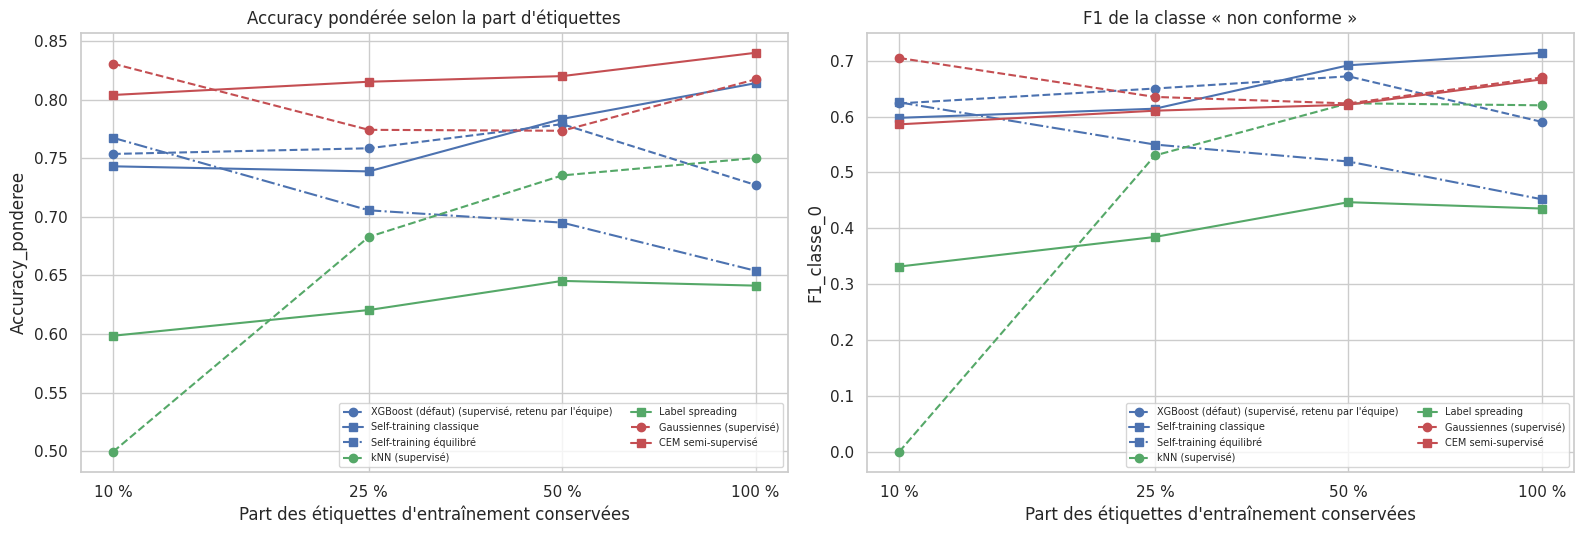

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5.5))
ssl.courbe_apprentissage(scores, paires, METRIQUE, "Accuracy pondérée selon la part d'étiquettes", ax=axes[0])
ssl.courbe_apprentissage(scores, paires, "F1_classe_0", "F1 de la classe « non conforme »", ax=axes[1])
plt.tight_layout(); savefig("courbe_apprentissage"); plt.show()

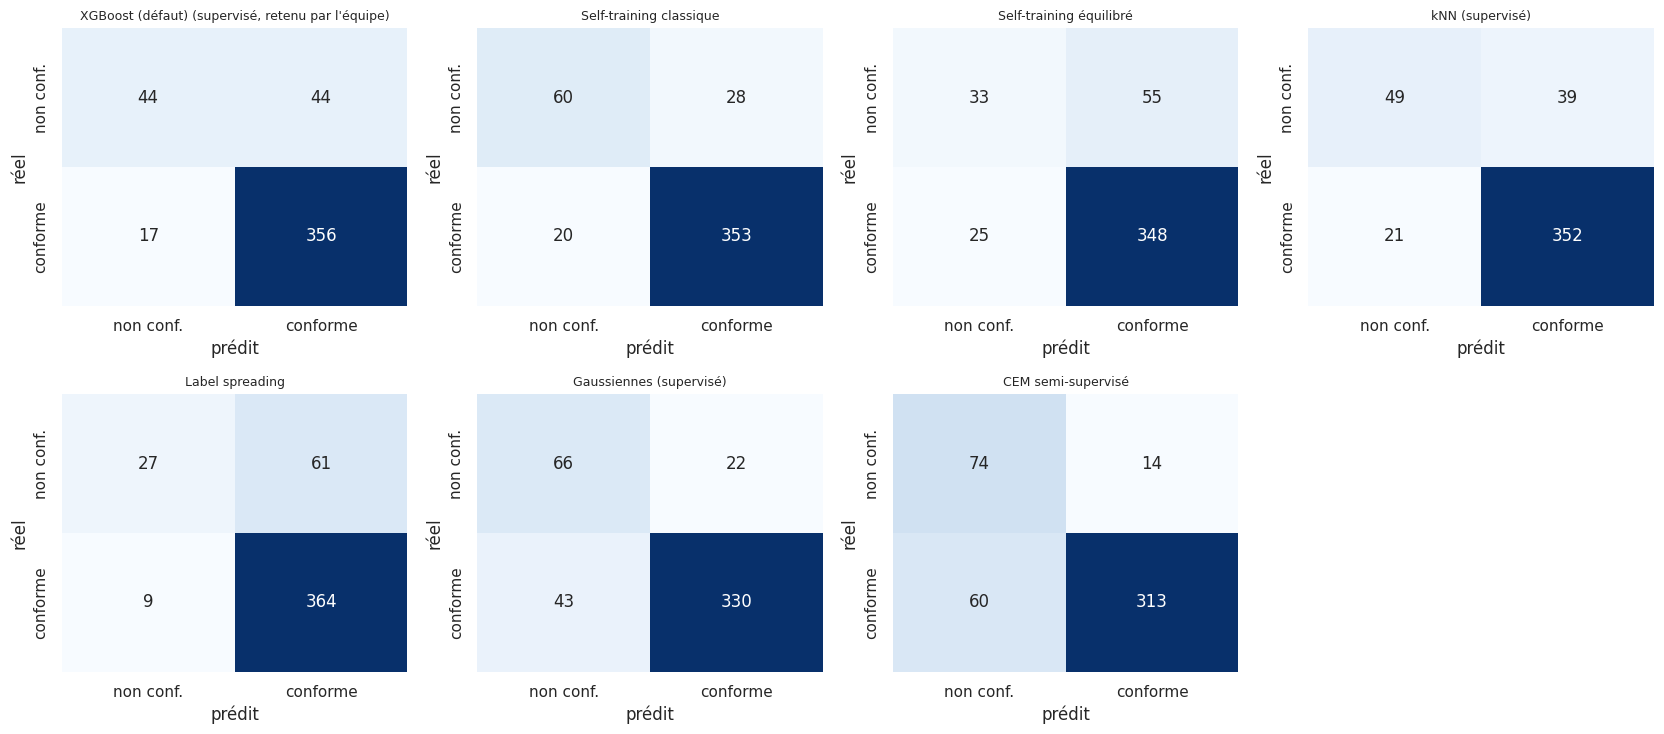

In [11]:
ssl.matrices_confusion(preds_cv, list(methodes), noms_classes=("non conf.", "conforme"))
savefig("confusion_cv"); plt.show()

In [12]:
gains = ssl.tableau_gains(preds_cv, paires, METRIQUE, FRACTIONS, n_boot=N_BOOT)
print("Gain en accuracy pondérée (semi-supervisé − sa référence supervisée), bootstrap apparié sur les publications")
gains.pivot_table(index=["famille", "semi-supervisé"], columns="fraction", values="gain").round(3)

Gain en accuracy pondérée (semi-supervisé − sa référence supervisée), bootstrap apparié sur les publications


fraction                                                0.10   0.25   0.50  \
famille                       semi-supervisé                                 
Discriminante (self-training) Self-training classique -0.011 -0.020  0.004   
                              Self-training équilibré  0.014 -0.053 -0.084   
Graphe                        Label spreading          0.099 -0.062 -0.090   
Générative                    CEM semi-supervisé      -0.027  0.041  0.047   

fraction                                                1.00  
famille                       semi-supervisé                  
Discriminante (self-training) Self-training classique  0.087  
                              Self-training équilibré -0.073  
Graphe                        Label spreading         -0.109  
Générative                    CEM semi-supervisé       0.023

In [13]:
gains[gains["fraction"] == 1.0].set_index("semi-supervisé")[["supervisé", "gain", "IC95_bas", "IC95_haut", "P(gain > 0)"]].round(3)

,supervisé,gain,IC95_bas,IC95_haut,P(gain > 0)
semi-supervisé,,,,,
Self-training classique,"XGBoost (défaut) (supervisé, retenu par l'équipe)",0.087,-0.121,0.223,0.806
Self-training équilibré,"XGBoost (défaut) (supervisé, retenu par l'équipe)",-0.073,-0.190,0.074,0.190
Label spreading,kNN (supervisé),-0.109,-0.203,0.000,0.022
CEM semi-supervisé,Gaussiennes (supervisé),0.023,-0.034,0.150,0.632


### 5.2 Analyse des résultats en validation croisée

**Rappel de lecture** : chaque méthode semi-supervisée se compare à **sa** référence (même couleur sur la courbe). Un gain n'est établi que si son IC à 95 % apparié exclut 0.

| Paire (100 % des étiquettes) | Acc. pondérée sup. → semi | Gain [IC95 apparié] | P(gain > 0) | Non conformes détectées / 88 |
|---|---|---|---|---|
| XGBoost équipe → self-training classique | 0,727 → **0,814** | **+0,087** [−0,12 ; +0,22] | 0,81 | 44 → **60** (fausses alertes 17 → 20) |
| XGBoost équipe → self-training équilibré | 0,727 → 0,654 | −0,073 [−0,19 ; +0,07] | 0,19 | 44 → 33 |
| kNN → label spreading | 0,750 → 0,641 | **−0,109** [−0,20 ; 0,00] | **0,02** | 49 → 27 |
| Gaussiennes → CEM | 0,817 → **0,840** | +0,023 [−0,03 ; +0,15] | 0,63 | 66 → 74 (fausses alertes 43 → 60) |

**1. Aucun gain n'est statistiquement établi** : tous les intervalles contiennent 0. Avec 88 non conformes d'entraînement réparties dans une dizaine de publications, l'incertitude reste grande.

**2. Self-training classique : le gain le plus net, mais seulement avec toutes les étiquettes.** Il détecte 16 non conformes de plus que le XGBoost de l'équipe pour 3 fausses alertes de plus. Contrairement à la théorie, il **n'aide pas quand les étiquettes sont rares** (−0,01 à 10 %, −0,02 à 25 %) : avec peu d'étiquettes, le XGBoost de départ est peu fiable et ses pseudo-étiquettes aussi. Le self-training ne vaut que ce que vaut son modèle de départ.

**3. Self-training équilibré : moins bon que la référence dès 25 %.** Cette variante avait été conçue pour corriger le biais observé avec l'ancienne définition (44 non conformes : seules des pseudo-étiquettes « conforme » étaient ajoutées). Avec la nouvelle définition, ce biais a disparu (voir 5.1) : forcer des pseudo-étiquettes « non conforme » revient à ajouter les **moins sûres**, donc plus d'erreurs.

**4. Label spreading : il dégrade le kNN** (−0,11, P(gain > 0) = 0,02, presque significatif), sauf à 10 % où le kNN seul ne détecte plus aucune non conforme. La lissité est pourtant vérifiée (2.3), mais la diffusion passe surtout par les zones denses, majoritairement conformes : les petits paquets de non conformes sont « noyés » (27 détectées sur 88 seulement).

**5. CEM : meilleur score en CV, petit gain non significatif.** Le gain apparaît à 25-50 % (+0,04 à +0,05), comme le prévoit la théorie (les gaussiennes estimées sur peu d'exemples sont instables et $U$ les stabilise), mais pas à 10 %. Le CEM détecte plus de non conformes mais fait aussi plus de fausses alertes : il **déplace le seuil** vers la classe minoritaire plus qu'il n'apprend une meilleure frontière.

**6. Les conclusions dépendent de la définition de la cible.** Avec l'ancienne définition (47 J à −20 °C, 44 non conformes), le label spreading était la meilleure méthode et le self-training ne servait à rien ; avec la définition actuelle, c'est l'inverse. À signaler dans le rapport : le classement des méthodes semi-supervisées n'est **pas robuste** sur cette base.

### 5.1 Diagnostic du self-training : quelles pseudo-étiquettes sont ajoutées ?

Pour comprendre le comportement des deux self-trainings, on regarde, sur tout le train, combien de pseudo-étiquettes de chaque classe ils ajoutent, comparé à la proportion réelle des classes.

In [14]:
X_S = jeux["X_lab"].iloc[jeux["train_idx"]]
Z_S, Z_U = prep_h.transform(X_S), prep_h.transform(jeux["X_unl"])
Z_SU = np.vstack([Z_S, Z_U]); y_SU = np.concatenate([y_tr.to_numpy(), -np.ones(len(Z_U), dtype=int)])

st = ssl.clone(methodes["Self-training classique"][0]).fit(Z_SU, y_SU)
pseudo = st.transduction_[len(Z_S):][st.labeled_iter_[len(Z_S):] > 0]
ste = ssl.clone(methodes["Self-training équilibré"][0]).fit(Z_SU, y_SU)
diag = pd.DataFrame({
    "classique": pd.Series(pseudo).value_counts().reindex([0, 1], fill_value=0),
    "équilibré": pd.Series(ste.n_pseudo_par_classe_).reindex([0, 1], fill_value=0),
    "vraies étiquettes (train)": y_tr.value_counts().reindex([0, 1]),
}).rename(index={0: "non conforme", 1: "conforme"})
diag.loc["part de non conformes"] = diag.loc["non conforme"] / diag.sum()
print(f"Non-étiquetées disponibles : {len(Z_U)}")
diag.round(3)

Non-étiquetées disponibles : 935


,classique,équilibré,vraies étiquettes (train)
non conforme,151.000,174.000,88.000
conforme,746.000,733.000,373.000
part de non conformes,0.168,0.192,0.191


### 5.2 bis Lecture du diagnostic

Avec la définition actuelle, le self-training **classique** ajoute environ **17 % de pseudo-étiquettes « non conforme »**, proche de la proportion réelle (19 %) : il **n'est plus biaisé** vers la classe majoritaire, contrairement à ce qu'on observait avec l'ancienne définition (44 non conformes, presque uniquement des pseudo-étiquettes « conforme »). C'est ce qui explique qu'il fonctionne maintenant.

Le self-training **équilibré** impose 19 % de non conformes : les pseudo-étiquettes supplémentaires sont celles dont le modèle est **le moins sûr**, d'où sa dégradation. **Leçon** : le pseudo-étiquetage équilibré est un remède au biais de confirmation, utile seulement quand ce biais existe.

## 6. Modèle retenu et évaluation finale sur le test

Application de la règle fixée en section 3, puis évaluation **une seule fois** sur le test du notebook 3. La **décision** porte sur trois modèles, tous entraînés sur le **même train** (+ $U$ pour le semi-supervisé) :
- le modèle **semi-supervisé retenu** ;
- **sa référence supervisée** (même famille) ;
- le **modèle retenu par l'équipe** dans le notebook 3, ré-entraîné ici avec le même prétraitement.

Les autres méthodes sont aussi évaluées sur le test, **pour information seulement** : la règle de choix ayant été fixée avant, ces scores ne doivent pas servir à changer de modèle (ce serait choisir sur le test).

In [15]:
semi = [p[2] for p in paires]
NOM_RETENU = s100.loc[semi, METRIQUE].idxmax()
famille, NOM_SUP_RETENU, _ = next(p for p in paires if p[2] == NOM_RETENU)
g_ret = gains[(gains["semi-supervisé"] == NOM_RETENU) & (gains["fraction"] == 1.0)].iloc[0]
UTILE = bool(g_ret["IC95_bas"] > 0)
print(f"Semi-supervisé retenu : {NOM_RETENU}  (famille : {famille})")
print(f"Gain CV vs {NOM_SUP_RETENU} : {g_ret['gain']:+.3f}  IC95 [{g_ret['IC95_bas']:+.3f} ; {g_ret['IC95_haut']:+.3f}]"
      f"  ->  {'gain significatif' if UTILE else 'gain NON significatif'}")

Semi-supervisé retenu : CEM semi-supervisé  (famille : Générative)
Gain CV vs Gaussiennes (supervisé) : +0.023  IC95 [-0.034 ; +0.150]  ->  gain NON significatif


In [16]:
NOMS_TEST = list(dict.fromkeys([NOM_RETENU, NOM_SUP_RETENU, NOM_REF_LONG]))
NOMS_INFO = [n for n in methodes if n not in NOMS_TEST]
recap_test, preds_test, modeles_test, prep_test = ssl.evaluation_test(jeux, methodes, NOMS_TEST + NOMS_INFO, n_boot=N_BOOT)
recap_test["rôle"] = ["décision" if n in NOMS_TEST else "information" for n in recap_test.index]
recap_test[["rôle", "Accuracy_ponderee", "Accuracy_ponderee IC95 bas", "Accuracy_ponderee IC95 haut",
            "F1_classe_0", "F1", "Recall", "ROC_AUC"]].round(3)

,rôle,Accuracy_ponderee,Accuracy_ponderee IC95 bas,Accuracy_ponderee IC95 haut,F1_classe_0,F1,Recall,ROC_AUC
CEM semi-supervisé,décision,0.565,0.241,1.0,0.293,0.624,0.484,0.655
Gaussiennes (supervisé),décision,0.593,0.259,1.0,0.314,0.671,0.538,0.619
"XGBoost (défaut) (supervisé, retenu par l'équipe)",décision,0.818,0.500,1.0,0.759,0.963,0.989,0.807
Self-training classique,information,0.765,0.500,1.0,0.692,0.958,1.000,0.718
Self-training équilibré,information,0.765,0.500,1.0,0.692,0.958,1.000,0.703
kNN (supervisé),information,0.818,0.500,1.0,0.759,0.963,0.989,0.814
Label spreading,information,0.818,0.500,1.0,0.759,0.963,0.989,0.787


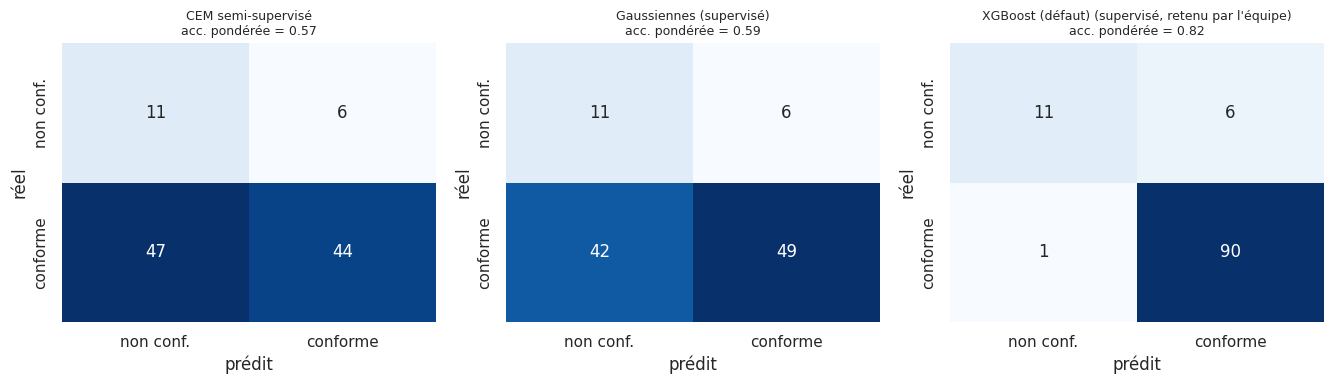

In [17]:
fig, axes = plt.subplots(1, len(NOMS_TEST), figsize=(4.5 * len(NOMS_TEST), 4))
for ax, nom in zip(np.atleast_1d(axes), NOMS_TEST):
    p = preds_test[preds_test["methode"] == nom]
    cm = ssl.confusion_matrix(p["y"], p["y_pred"], labels=[0, 1])
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax,
                xticklabels=["non conf.", "conforme"], yticklabels=["non conf.", "conforme"])
    ax.set_title(f"{nom}\nacc. pondérée = {recap_test.loc[nom, 'Accuracy_ponderee']:.2f}", fontsize=9)
    ax.set_xlabel("prédit"); ax.set_ylabel("réel")
plt.tight_layout(); savefig("confusion_test"); plt.show()

In [18]:
# Le test est-il représentatif ? Répartition des soudures de test par publication, et erreurs par modèle
erreurs = (preds_test.assign(erreur=lambda d: (d["y"] != d["y_pred"]).astype(int))
           .pivot_table(index="groupe", columns="methode", values="erreur", aggfunc="sum")[NOMS_TEST])
compo = preds_test[preds_test["methode"] == NOM_RETENU].groupby("groupe")["y"].agg(
    n="size", non_conformes=lambda s: int((s == 0).sum()))
compo.join(erreurs.add_prefix("erreurs : ")).sort_values("n", ascending=False)

,n,non_conformes,erreurs : CEM semi-supervisé,erreurs : Gaussiennes (supervisé),"erreurs : XGBoost (défaut) (supervisé, retenu par l'équipe)"
groupe,,,,,
Evans-AlTi-1994,84,6,49,46,6
PantK-1990,9,9,0,0,0
EvHtIp1979,7,0,0,0,0
Chandel&-1985,6,2,4,2,1
Blond&-1984,1,0,0,0,0
EvansLetterC+.5Moch1,1,0,0,0,0


In [19]:
# Pour information : score publié par le notebook 3 (imputation apprise sur le train seul, sans standardisation)
publie = pd.read_csv(P_REF / METHODE_REF / "test_recap_metriques.csv", sep=";", encoding="utf-8-sig", index_col=0)
publie

,CV (nouveaux découpages),Test,Baseline sur le test
F1,0.936666,0.968085,0.914573
Accuracy_ponderee,0.770368,0.823529,0.500000
Precision,0.924960,0.938144,0.842593
Recall,0.951665,1.000000,1.000000
ROC_AUC,0.912327,0.804137,0.500000


### 6.1 Analyse de l'évaluation finale

**La règle fixée à l'avance retient le CEM** (meilleure accuracy pondérée en CV : 0,840), mais son gain sur sa référence n'est **pas significatif**.

**Sur le test, le CEM s'effondre** : accuracy pondérée 0,565 (gaussiennes supervisées : 0,593), contre **0,818 pour le XGBoost de l'équipe**. Ce dernier score est cohérent avec celui publié par le notebook 3 (0,824) : notre pipeline reproduit bien le travail de l'équipe.

**Pourquoi un tel écart entre CV et test ?** Le tableau par publication est éclairant : le test ne contient que **6 publications**, et **84 soudures sur 108 viennent d'une seule** (*Evans-AlTi-1994*, une étude des effets de Al et Ti). Le CEM s'y trompe 49 fois (il classe « non conformes » des soudures conformes), le XGBoost 6 fois. Les modèles gaussiens supposent que chaque classe est une gaussienne ; une série de soudures dont la composition sort de la zone où ces gaussiennes ont été estimées est mal classée, alors que les arbres de décision extrapolent plus prudemment. Le test mesure donc surtout **la capacité à généraliser à cette publication**.

**Lecture complémentaire (non décisionnelle)** : sur le test, le self-training classique (0,765) ne fait pas mieux que le XGBoost de l'équipe dont il part ; kNN et label spreading font jeu égal avec lui (0,818).

**Limites de ce test** : 17 non conformes seulement, presque toutes dans 2 publications ; les IC bootstrap sur les publications sont **dégénérés** ([0,5 ; 1]) car un tirage peut ne contenir aucune non conforme. Le test est donc peu informatif pour départager des méthodes ; la validation croisée (461 soudures, 5 plis) reste la base de la comparaison, et le test sert de **garde-fou**, qu'il a joué ici : il montre que l'avantage du CEM en CV ne se généralise pas.

**Décision** : on conserve le **XGBoost supervisé de l'équipe** pour `Charpy conforme`. Aucune méthode semi-supervisée n'apporte de gain significatif, et la méthode retenue par notre règle est nettement moins bonne sur le test. Cette recommandation est enregistrée dans le JSON.

## 7. Sauvegarde (`05_reporting/semi_supervise/Charpy_conforme/`)

Même logique que les notebooks supervisés :
- `modele_retenu_ssl.json` : méthode retenue et ses hyperparamètres, référence supervisée, gains, scores CV et test, paramètres du protocole ;
- `modele_final_ssl.joblib` : prétraitement + modèle retenu entraînés sur tout le train (+ $U$), réutilisables sans ré-entraîner ;
- CSV : prédictions hors-pli, scores par méthode et par fraction, gains appariés, test, vérification des hypothèses.

In [20]:
def params_modele(est):
    '''Hyperparamètres utiles d'une méthode (on ne garde que les valeurs simples).'''
    p = est.get_params(deep=False)
    out = {k: v for k, v in p.items() if isinstance(v, (int, float, str, bool, type(None)))}
    if "estimator" in p:
        out["modele_de_base"] = NOM_REF
    if hasattr(est, "steps"):
        out = {f"{n}__{k}": v for n, s in est.steps for k, v in s.get_params(deep=False).items()
               if isinstance(v, (int, float, str, bool, type(None)))}
    return out

infos = {
    "cible": CIBLE,
    "definition_cible": "47 J à -40 °C (EN ISO 2560-A) ; interpolation de T(47 J) entre T(28 J) et T(100 J) — notebook 2, section 3.1",
    "type": "classification semi-supervisée",
    "score_de_selection": METRIQUE,
    "regle_de_choix": "meilleure accuracy pondérée en CV à 100 % des étiquettes ; utile si la borne basse de l'IC95 du gain apparié > 0",
    "modele_retenu": NOM_RETENU,
    "famille": famille,
    "hyperparametres_retenu": params_modele(methodes[NOM_RETENU][0]),
    "reference_supervisee": NOM_SUP_RETENU,
    "modele_equipe": {"nom": NOM_REF, "hyperparametres": ref["hyperparametres_retenu"],
                      "source": str(P_REF / METHODE_REF / "modele_retenu.json")},
    "gain_cv_vs_reference": {k: g_ret[k] for k in ["gain", "IC95_bas", "IC95_haut", "P(gain > 0)"]},
    "gain_significatif": UTILE,
    "score_cv_100pct": s100.drop(columns=[f"{METRIQUE} IC95"]).to_dict(orient="index"),
    "ic95_cv_100pct": {m: list(v) for m, v in ic.items()},
    "hyperparametres_toutes_methodes": {n: params_modele(e) for n, (e, _) in methodes.items()},
    "score_test": recap_test.drop(columns="rôle").to_dict(orient="index"),
    "recommandation": (f"{NOM_RETENU} (semi-supervisé)" if UTILE and
                       recap_test.loc[NOM_RETENU, METRIQUE] >= recap_test.loc[NOM_REF_LONG, METRIQUE]
                       else f"{NOM_REF} supervisé (notebook 3) : aucun gain semi-supervisé significatif en CV"
                            + ("" if recap_test.loc[NOM_RETENU, METRIQUE] >= recap_test.loc[NOM_REF_LONG, METRIQUE]
                               else ", et le semi-supervisé retenu est moins bon sur le test")),
    "n_etiquetees_train": int(len(y_tr)), "n_etiquetees_test": int(len(y_te)),
    "n_non_etiquetees": int(len(jeux["X_unl"])), "n_non_etiquetees_exclues_test": jeux["n_unl_exclues_test"],
    "variables_utilisees": jeux["X_lab"].columns.tolist() + ["CE_IIW", "courant"],
    "verification_hypotheses": hypotheses.to_dict(),
    "RANDOM_STATE": RANDOM_STATE, "N_FOLDS": N_FOLDS, "FRACTIONS": FRACTIONS,
    "N_TIRAGES": N_TIRAGES, "N_BOOT": N_BOOT,
    "split": str(P_REF / "split_train_test.csv"),
}
dossier = ssl.enregistrer_ssl(P_SORTIE, infos, preds_cv, scores, gains, recap_test, preds_test,
                              modeles_test[NOM_RETENU], prep_test, hypotheses)
print("Enregistré dans", dossier)
print(sorted(p.name for p in dossier.iterdir()))

Enregistré dans ../1. Données/05_reporting/semi_supervise/Charpy_conforme
['cv_gains_apparies.csv', 'cv_predictions.csv', 'cv_scores_par_methode_et_fraction.csv', 'modele_final_ssl.joblib', 'modele_retenu_ssl.json', 'test_predictions.csv', 'test_recap_metriques.csv', 'verification_hypotheses.csv']


## 8. Conclusion

**Ce que montre ce notebook**
- Les hypothèses du semi-supervisé ne sont **que partiellement vérifiées** sur cette base : la lissité tient (y compris entre publications), mais près de la moitié des soudures non étiquetées décrivent des familles d'aciers sans aucun résultat Charpy, et elles rapprochent peu le test des données d'entraînement.
- **Aucune des trois familles du cours n'apporte de gain statistiquement significatif** en validation croisée. Les deux méthodes les plus prometteuses (self-training classique : +0,09 ; CEM : +0,02) ont des intervalles qui contiennent 0, et le label spreading dégrade même sa référence.
- **La méthode retenue par la règle (CEM) ne se généralise pas** au test, dominé par une publication dont la composition sort de la zone apprise par les gaussiennes. Le **XGBoost supervisé de l'équipe reste le meilleur modèle**.
- Le classement des méthodes dépend de la **définition de la cible** (−20 °C ou −40 °C) : sur une base aussi petite, les conclusions sur le semi-supervisé sont fragiles.

**Pourquoi c'est un résultat valable** : la littérature montre que les données non étiquetées n'aident que si leurs hypothèses sont satisfaites, et peuvent même dégrader les performances sinon (Singh et al., 2008 ; Oliver et al., 2018 ; van Engelen & Hoos, 2020). Ici, le principal obstacle n'est pas le manque d'étiquettes mais la **généralisation à des publications jamais vues**, que des soudures non étiquetées issues d'autres études ne peuvent pas résoudre.

**Pistes d'amélioration**
1. Régler les hyperparamètres des méthodes semi-supervisées (seuil, $k$, $\alpha$, nombre de composantes) par validation croisée **imbriquée**, pour ne pas les choisir sur les données d'évaluation.
2. Construire le graphe du label spreading dans un meilleur espace (variables métallurgiques clés, ou proximités d'une forêt aléatoire), plutôt qu'en distance euclidienne sur toutes les variables.
3. Ajuster le seuil de décision (0,5 par défaut) pour favoriser la détection des non conformes, l'erreur la plus coûteuse.
4. Vérifier la robustesse des conclusions avec une autre température d'exigence (−20 °C, −60 °C).

**Fichiers produits** : `05_reporting/semi_supervise/Charpy_conforme/` (JSON du modèle retenu et de la recommandation, prédictions, scores, gains, hypothèses, modèle entraîné) et `3. Résultats/figures/ssl_charpy_*.png`.

## Références

**Cours**
- M. Tami, *CM8 – Semi-supervised learning*, CentraleSupélec.

**Ouvrages (cités dans le cours)**
- O. Chapelle, B. Schölkopf, A. Zien (2006). *Semi-Supervised Learning*. MIT Press.
- X. Zhu, A. B. Goldberg (2009). *Introduction to Semi-Supervised Learning*. Morgan & Claypool. [doi:10.2200/S00196ED1V01Y200906AIM006](https://doi.org/10.2200/S00196ED1V01Y200906AIM006)
- M.-R. Amini, N. Usunier (2015). *Learning with Partially Labeled and Interdependent Data*. Springer.

**Méthodes**
- D. Yarowsky (1995). *Unsupervised word sense disambiguation rivaling supervised methods*. ACL — origine du self-training.
- G. Celeux, G. Govaert (1992). *A classification EM algorithm for clustering and two stochastic versions*. Computational Statistics & Data Analysis, 14(3), 315-332 — CEM.
- A. P. Dempster, N. M. Laird, D. B. Rubin (1977). *Maximum likelihood from incomplete data via the EM algorithm*. JRSS B, 39(1), 1-38.
- D. Zhou, O. Bousquet, T. N. Lal, J. Weston, B. Schölkopf (2004). [*Learning with local and global consistency*](https://proceedings.neurips.cc/paper/2003/hash/87682805257e619d49b8e0dfdc14affa-Abstract.html). NeurIPS 16 — `LabelSpreading`.
- [scikit-learn User Guide – Semi-supervised learning](https://scikit-learn.org/stable/modules/semi_supervised.html)

**Quand le semi-supervisé aide (ou non)**
- A. Singh, R. Nowak, X. Zhu (2008). *Unlabeled data: Now it helps, now it doesn't*. NeurIPS 21.
- A. Oliver, A. Odena, C. Raffel, E. D. Cubuk, I. Goodfellow (2018). *Realistic evaluation of deep semi-supervised learning algorithms*. NeurIPS 31.
- J. E. van Engelen, H. H. Hoos (2020). *A survey on semi-supervised learning*. Machine Learning, 109, 373-440. [doi:10.1007/s10994-019-05855-6](https://doi.org/10.1007/s10994-019-05855-6)

**Évaluation**
- G. Forman, M. Scholz (2010). *Apples-to-apples in cross-validation studies: pitfalls in classifier performance measurement*. ACM SIGKDD Explorations, 12(1), 49-57.

**Cible Charpy**
- T. Cool (1996). *Design of Steel Weld Deposits*, thèse de doctorat, University of Cambridge, chapitre 6.
- EN ISO 2560 : Produits consommables pour le soudage — Électrodes enrobées pour le soudage manuel à l'arc des aciers non alliés et à grains fins — Classification.